In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Reproducibility and display settings
RANDOM_STATE = 42

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.4f}".format)

sns.set_theme(style="whitegrid")

# Project paths
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = PROJECT_ROOT / "data" / "creditcard.csv"

# Load dataset
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at: {DATA_PATH}\n"
        "Place creditcard.csv inside the project's data/ folder."
    )

df = pd.read_csv(DATA_PATH)

print(f"Dataset loaded successfully!")
print(f"Shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"Location: {DATA_PATH}")

Dataset loaded successfully!
Shape: 284,807 rows × 31 columns
Location: c:\Users\Administrator\Self Study\fraud_detection\fraud-detection\fraud-detection\data\creditcard.csv


In [2]:
# Preview the first 5 transactions
display(df.head())

# Inspect column names and data types
print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0000,-1.3598,-0.0728,2.5363,1.3782,-0.3383,0.4624,0.2396,0.0987,0.3638,0.0908,-0.5516,-0.6178,-0.9914,-0.3112,1.4682,-0.4704,0.2080,0.0258,0.4040,0.2514,-0.0183,0.2778,-0.1105,0.0669,0.1285,-0.1891,0.1336,-0.0211,149.6200,0
1,0.0000,1.1919,0.2662,0.1665,0.4482,0.0600,-0.0824,-0.0788,0.0851,-0.2554,-0.1670,1.6127,1.0652,0.4891,-0.1438,0.6356,0.4639,-0.1148,-0.1834,-0.1458,-0.0691,-0.2258,-0.6387,0.1013,-0.3398,0.1672,0.1259,-0.0090,0.0147,2.6900,0
2,1.0000,-1.3584,-1.3402,1.7732,0.3798,-0.5032,1.8005,0.7915,0.2477,-1.5147,0.2076,0.6245,0.0661,0.7173,-0.1659,2.3459,-2.8901,1.1100,-0.1214,-2.2619,0.5250,0.2480,0.7717,0.9094,-0.6893,-0.3276,-0.1391,-0.0554,-0.0598,378.6600,0
3,1.0000,-0.9663,-0.1852,1.7930,-0.8633,-0.0103,1.2472,0.2376,0.3774,-1.3870,-0.0550,-0.2265,0.1782,0.5078,-0.2879,-0.6314,-1.0596,-0.6841,1.9658,-1.2326,-0.2080,-0.1083,0.0053,-0.1903,-1.1756,0.6474,-0.2219,0.0627,0.0615,123.5000,0
4,2.0000,-1.1582,0.8777,1.5487,0.4030,-0.4072,0.0959,0.5929,-0.2705,0.8177,0.7531,-0.8228,0.5382,1.3459,-1.1197,0.1751,-0.4514,-0.2370,-0.0382,0.8035,0.4085,-0.0094,0.7983,-0.1375,0.1413,-0.2060,0.5023,0.2194,0.2152,69.9900,0



Column names:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null 

In [3]:
# Check missing values
missing_values = df.isnull().sum()

missing_summary = (
    missing_values[missing_values > 0]
    .sort_values(ascending=False)
)

print("Missing values:")
if missing_summary.empty:
    print("No missing values found.")
else:
    display(missing_summary)

# Check exact duplicate rows
duplicate_count = df.duplicated().sum()

print(f"\nExact duplicate rows: {duplicate_count:,}")
print(f"Percentage of rows duplicated: {duplicate_count / len(df) * 100:.4f}%")

# Check target validity
print("\nTarget values:")
print(df["Class"].value_counts().sort_index())

print("\nUnique target values:", sorted(df["Class"].unique()))

Missing values:
No missing values found.

Exact duplicate rows: 1,081
Percentage of rows duplicated: 0.3796%

Target values:
Class
0    284315
1       492
Name: count, dtype: int64

Unique target values: [np.int64(0), np.int64(1)]


In [4]:
# Inspect duplicate rows without modifying df
duplicate_rows = df[df.duplicated(keep=False)].copy()

print(f"Rows belonging to duplicate groups: {len(duplicate_rows):,}")

print("\nClass distribution among rows in duplicate groups:")
display(
    duplicate_rows["Class"]
    .value_counts()
    .sort_index()
    .rename("Count")
    .to_frame()
)

print("\nClass distribution among all rows:")
display(
    df["Class"]
    .value_counts()
    .sort_index()
    .rename("Count")
    .to_frame()
)

# Count distinct duplicated records and their group sizes
duplicate_groups = (
    df.groupby(df.columns.tolist(), dropna=False)
    .size()
    .loc[lambda counts: counts > 1]
    .sort_values(ascending=False)
)

print(f"\nNumber of distinct duplicated row groups: {len(duplicate_groups):,}")

print("\nMost frequent duplicate group sizes:")
display(duplicate_groups.value_counts().sort_index().rename_axis("Copies per row").to_frame("Number of groups"))

Rows belonging to duplicate groups: 1,854

Class distribution among rows in duplicate groups:


,Count
Class,
0,1822
1,32



Class distribution among all rows:


,Count
Class,
0,284315
1,492



Number of distinct duplicated row groups: 773

Most frequent duplicate group sizes:


,Number of groups
Copies per row,
2,611
3,66
4,81
5,10
6,1
9,2
18,2


,Transaction Type,Count,Percentage (%)
0,Legitimate,284315,99.8273
1,Fraudulent,492,0.1727


Total transactions: 284,807
Fraud prevalence: 0.1727%
Legitimate-to-fraud ratio: 577.88:1


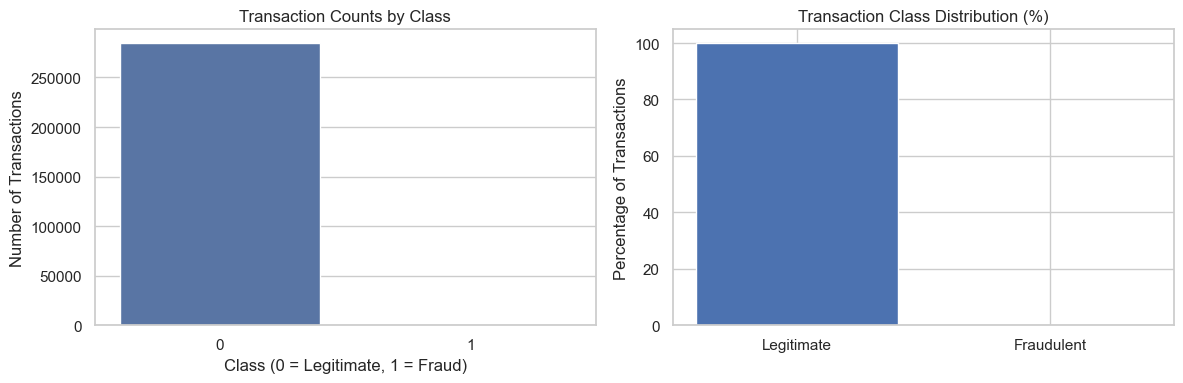

In [5]:
# Count each target class
class_counts = df["Class"].value_counts().sort_index()

# Calculate class percentages
class_percentages = df["Class"].value_counts(normalize=True).sort_index() * 100

class_summary = pd.DataFrame({
    "Transaction Type": ["Legitimate", "Fraudulent"],
    "Count": [class_counts[0], class_counts[1]],
    "Percentage (%)": [
        class_percentages[0],
        class_percentages[1],
    ],
})

display(class_summary)

# Calculate imbalance ratio
imbalance_ratio = class_counts[0] / class_counts[1]

print(f"Total transactions: {len(df):,}")
print(f"Fraud prevalence: {class_percentages[1]:.4f}%")
print(f"Legitimate-to-fraud ratio: {imbalance_ratio:.2f}:1")

# Visualize class distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(data=df, x="Class", hue="Class", legend=False, ax=axes[0])
axes[0].set_title("Transaction Counts by Class")
axes[0].set_xlabel("Class (0 = Legitimate, 1 = Fraud)")
axes[0].set_ylabel("Number of Transactions")

axes[1].bar(
    ["Legitimate", "Fraudulent"],
    [class_percentages[0], class_percentages[1]],
)
axes[1].set_title("Transaction Class Distribution (%)")
axes[1].set_ylabel("Percentage of Transactions")

plt.tight_layout()
plt.show()

Transaction Amount Summary:


,Amount
count,284807.0000
mean,88.3496
std,250.1201
min,0.0000
25%,5.6000
50%,22.0000
75%,77.1650
max,25691.1600



Amount statistics by class:


,count,mean,median,std,min,max
Class,,,,,,
Legitimate,284315,88.2910,22.0000,250.1051,0.0000,25691.1600
Fraudulent,492,122.2113,9.2500,256.6833,0.0000,2125.8700


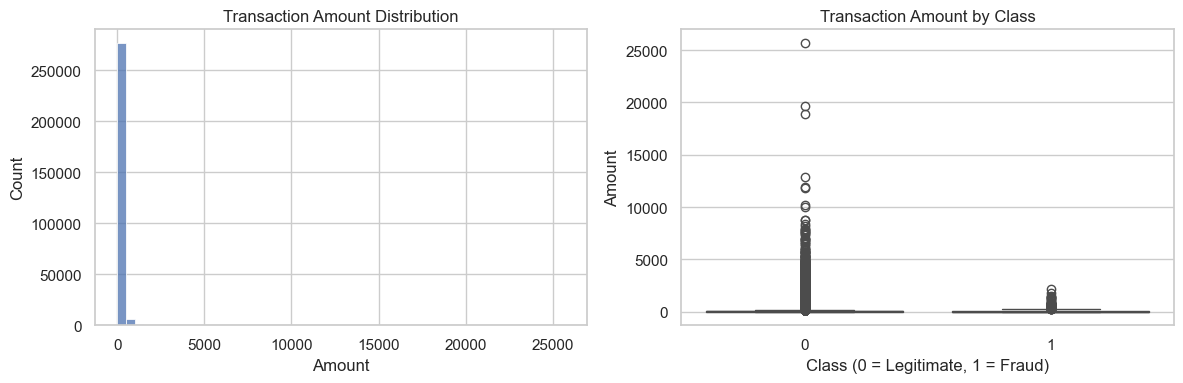

In [6]:
# Explore transaction amount distributions
print("Transaction Amount Summary:")
display(df["Amount"].describe().to_frame())

print("\nAmount statistics by class:")
display(
    df.groupby("Class")["Amount"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .rename(index={0: "Legitimate", 1: "Fraudulent"})
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(data=df, x="Amount", bins=50, ax=axes[0])
axes[0].set_title("Transaction Amount Distribution")
axes[0].set_xlabel("Amount")

sns.boxplot(data=df, x="Class", y="Amount", hue="Class", legend=False, ax=axes[1])
axes[1].set_title("Transaction Amount by Class")
axes[1].set_xlabel("Class (0 = Legitimate, 1 = Fraud)")
axes[1].set_ylabel("Amount")

plt.tight_layout()
plt.show()

Transaction Time Summary:


,Time
count,284807.0000
mean,94813.8596
std,47488.1460
min,0.0000
25%,54201.5000
50%,84692.0000
75%,139320.5000
max,172792.0000



Time statistics by class:


,count,mean,median,std,min,max
Class,,,,,,
Legitimate,284315,94838.2023,84711.0000,47484.0158,0.0000,172792.0000
Fraudulent,492,80746.8069,75568.5000,47835.3651,406.0000,170348.0000


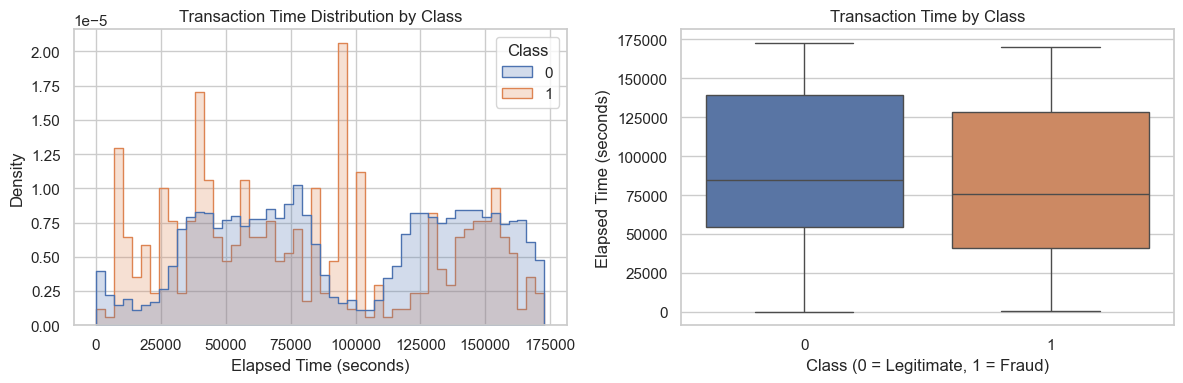

In [7]:
# Explore transaction time
print("Transaction Time Summary:")
display(df["Time"].describe().to_frame())

print("\nTime statistics by class:")
display(
    df.groupby("Class")["Time"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .rename(index={0: "Legitimate", 1: "Fraudulent"})
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(
    data=df,
    x="Time",
    bins=50,
    hue="Class",
    element="step",
    stat="density",
    common_norm=False,
    ax=axes[0],
)
axes[0].set_title("Transaction Time Distribution by Class")
axes[0].set_xlabel("Elapsed Time (seconds)")

sns.boxplot(
    data=df,
    x="Class",
    y="Time",
    hue="Class",
    legend=False,
    ax=axes[1],
)
axes[1].set_title("Transaction Time by Class")
axes[1].set_xlabel("Class (0 = Legitimate, 1 = Fraud)")
axes[1].set_ylabel("Elapsed Time (seconds)")

plt.tight_layout()
plt.show()

,Legitimate Mean,Fraudulent Mean,Mean Difference,Absolute Difference
V3,0.0122,-7.0333,-7.0455,7.0455
V14,0.0121,-6.9717,-6.9838,6.9838
V17,0.0115,-6.6658,-6.6774,6.6774
V12,0.0108,-6.2594,-6.2702,6.2702
V10,0.0098,-5.6769,-5.6867,5.6867
V7,0.0096,-5.5687,-5.5784,5.5784
V1,0.0083,-4.7719,-4.7802,4.7802
V4,-0.0079,4.5420,4.5499,4.5499
V16,0.0072,-4.1399,-4.1471,4.1471
V11,-0.0066,3.8002,3.8067,3.8067


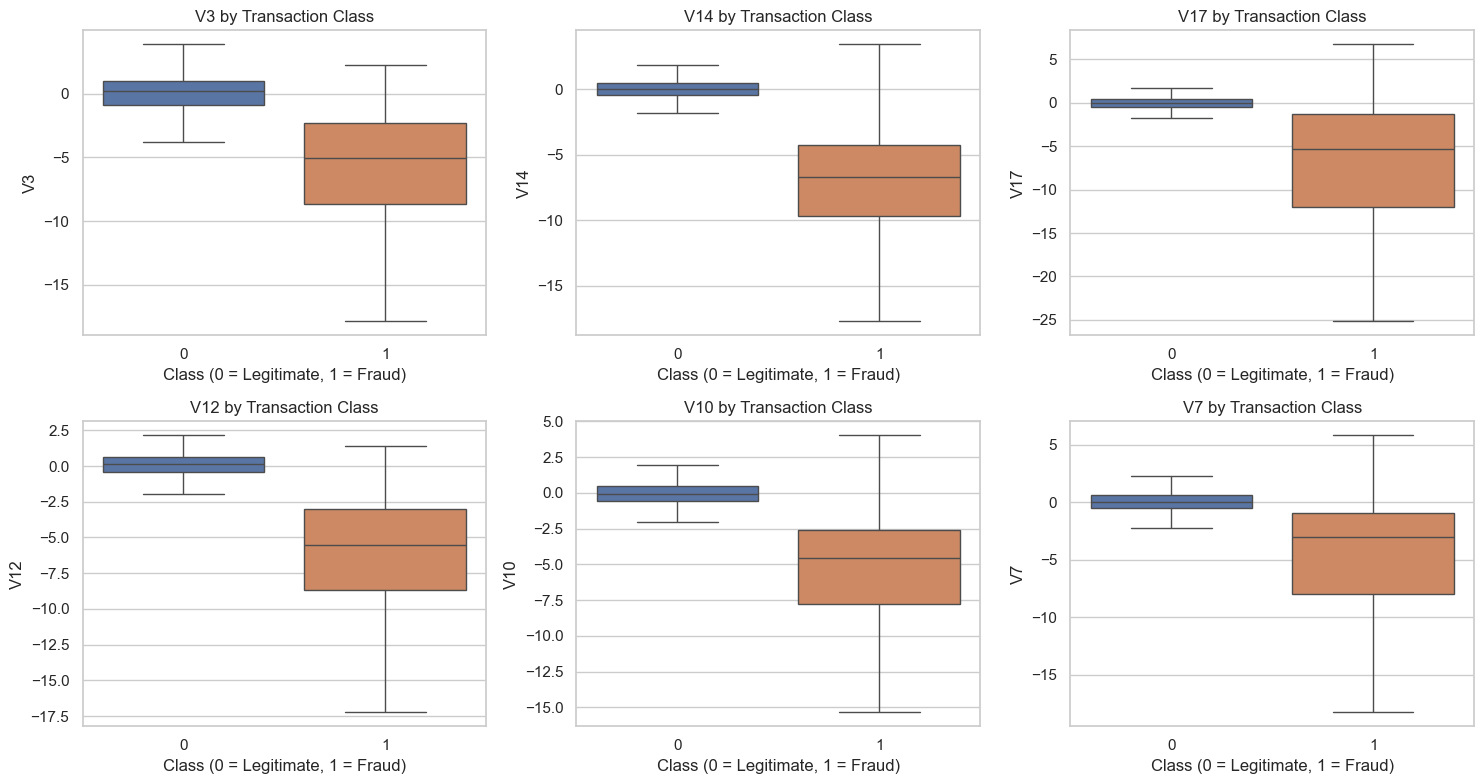

In [8]:
# Compare V1–V28 distributions by class
v_features = [f"V{i}" for i in range(1, 29)]

feature_summary = df.groupby("Class")[v_features].mean().T
feature_summary.columns = ["Legitimate Mean", "Fraudulent Mean"]
feature_summary["Mean Difference"] = (
    feature_summary["Fraudulent Mean"] - feature_summary["Legitimate Mean"]
)
feature_summary["Absolute Difference"] = feature_summary["Mean Difference"].abs()

display(
    feature_summary.sort_values(
        "Absolute Difference", ascending=False
    ).round(4)
)

# Plot the 6 features with the largest absolute difference in class means
top_features = feature_summary.nlargest(6, "Absolute Difference").index.tolist()

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for feature, ax in zip(top_features, axes.flat):
    sns.boxplot(
        data=df,
        x="Class",
        y=feature,
        hue="Class",
        legend=False,
        showfliers=False,
        ax=ax,
    )
    ax.set_title(f"{feature} by Transaction Class")
    ax.set_xlabel("Class (0 = Legitimate, 1 = Fraud)")

plt.tight_layout()
plt.show()

,Correlation with Class
V17,-0.3265
V14,-0.3025
V12,-0.2606
V10,-0.2169
V16,-0.1965
V3,-0.1930
V7,-0.1873
V11,0.1549
V4,0.1334
V18,-0.1115


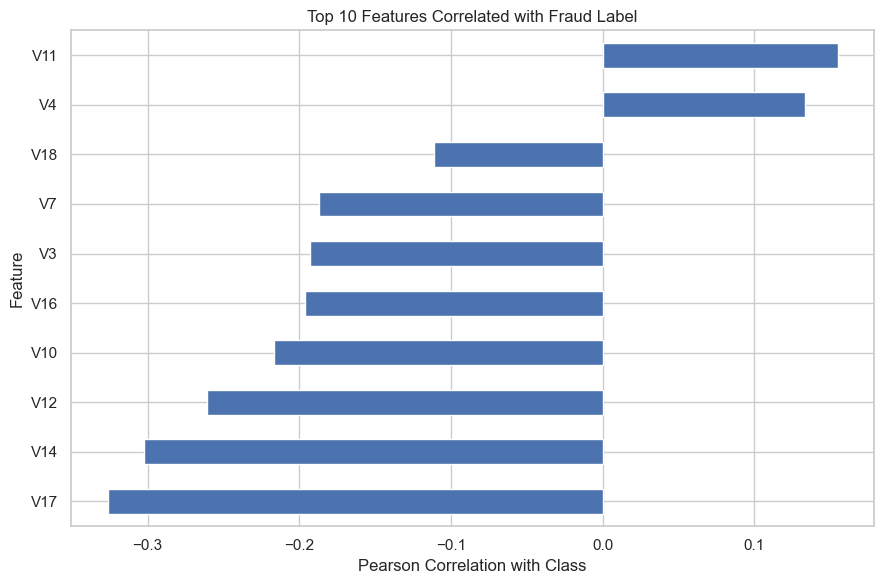

In [9]:
# Correlation of numeric features with the target
target_correlations = (
    df.corr(numeric_only=True)["Class"]
    .drop("Class")
    .sort_values(key=lambda s: s.abs(), ascending=False)
)

display(
    target_correlations.rename("Correlation with Class")
    .to_frame()
    .round(4)
)

# Plot the 10 features with the strongest absolute correlations
top_correlations = target_correlations.head(10).sort_values()

plt.figure(figsize=(9, 6))
top_correlations.plot(kind="barh")
plt.title("Top 10 Features Correlated with Fraud Label")
plt.xlabel("Pearson Correlation with Class")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

,Feature 1,Feature 2,Correlation,Absolute Correlation
83,V2,Amount,-0.5314,0.5314
2,Time,V3,-0.4196,0.4196
203,V7,Amount,0.3973,0.3973
158,V5,Amount,-0.3864,0.3864
398,V20,Amount,0.3394,0.3394
10,Time,V11,-0.2477,0.2477
24,Time,V25,-0.2331,0.2331
56,V1,Amount,-0.2277,0.2277
181,V6,Amount,0.2160,0.2160
109,V3,Amount,-0.2109,0.2109


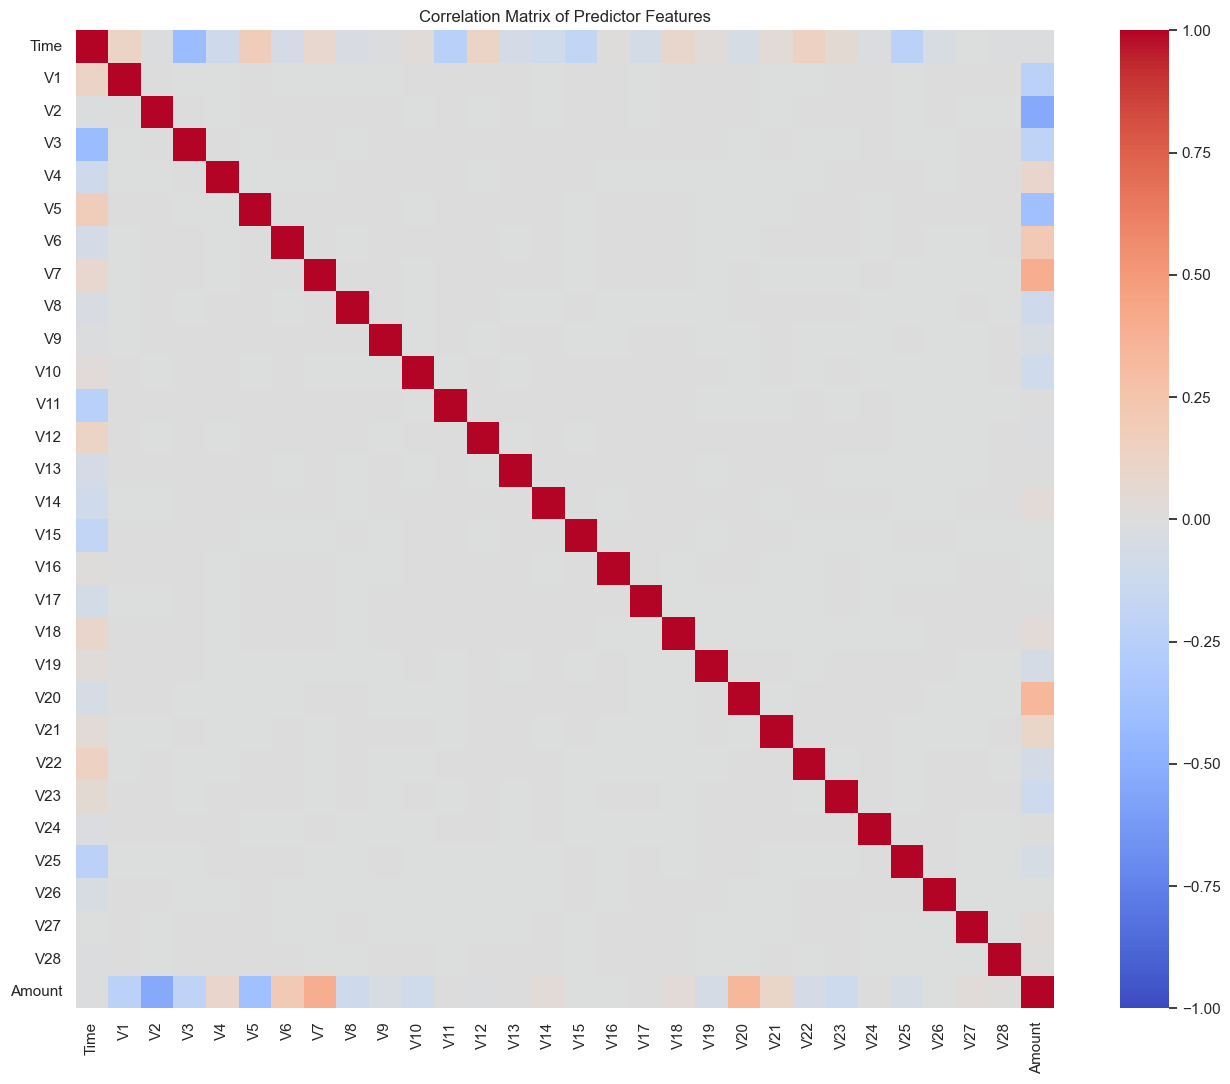

In [10]:
# Correlations among predictor features only
predictor_columns = [col for col in df.columns if col != "Class"]
predictor_corr = df[predictor_columns].corr()

# Extract unique feature pairs, excluding the diagonal
upper_mask = np.triu(np.ones(predictor_corr.shape, dtype=bool), k=1)
correlation_pairs = (
    predictor_corr.where(upper_mask)
    .stack()
    .rename("Correlation")
    .reset_index()
    .rename(columns={"level_0": "Feature 1", "level_1": "Feature 2"})
)

correlation_pairs["Absolute Correlation"] = correlation_pairs["Correlation"].abs()

display(
    correlation_pairs
    .sort_values("Absolute Correlation", ascending=False)
    .head(15)
    .round(4)
)

# Visualize the predictor correlation matrix
plt.figure(figsize=(14, 11))
sns.heatmap(
    predictor_corr,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    xticklabels=True,
    yticklabels=True,
)
plt.title("Correlation Matrix of Predictor Features")
plt.tight_layout()
plt.show()

## Exploratory Data Analysis — Key Findings

### Dataset Overview
- **Total transactions:** 284,807
- **Predictor columns:** 30 (`Time`, `V1`–`V28`, and `Amount`)
- **Target:** `Class` (0 = legitimate, 1 = fraudulent)
- **Missing values:** None detected
- **Exact duplicate rows:** 1,081 extra copies identified

### Class Imbalance
- Legitimate transactions: 284,315 (99.8273%)
- Fraudulent transactions: 492 (0.1727%)
- Legitimate-to-fraud ratio: approximately 577.88:1

This extreme imbalance makes accuracy alone unsuitable as the main evaluation metric.

### Transaction Amount
- Mean: 88.3496
- Median: 22.0000
- Maximum: 25,691.16
- Fraudulent transactions have a higher mean amount but a lower median than legitimate transactions.

The amount distribution is strongly right-skewed, and transaction amount alone is unlikely to distinguish all fraudulent transactions.

### Transaction Time
- Time ranges from 0 to 172,792 seconds.
- Fraudulent transactions have a lower median elapsed time than legitimate transactions.
- The column represents elapsed time, not a direct calendar timestamp or clock time.

### Feature Relationships with Fraud
- The strongest absolute Pearson correlations with the target include V17 (-0.3265), V14 (-0.3025), and V12 (-0.2606).
- V11 (+0.1549) and V4 (+0.1334) have the strongest positive correlations in the reported results.
- These are descriptive associations, not proof of causal relationships or definitive feature importance.

### Predictor Correlations
- The strongest reported pairwise correlation is between V2 and Amount (-0.5314).
- No pair in the top 15 has an absolute correlation above 0.6.
- Feature removal is not justified by these correlations alone.

### Preprocessing Considerations
- Preserve the original dataset during EDA.
- Handle exact duplicates in the preprocessing notebook, keeping one copy of each identical row, as previously decided.
- Investigate scaling and treatment of the Amount and Time columns before model training.
- Use an evaluation strategy and metrics appropriate for rare-event classification.
- Avoid making final feature-selection decisions based solely on EDA statistics.